Break dates: ['2021-12-13', '2021-12-20', '2022-01-04', '2022-01-19']
Break indices: [12, 19, 34, 49]
Segment bounds: [(0, 12), (12, 19), (19, 34), (34, 49), (49, 63)]


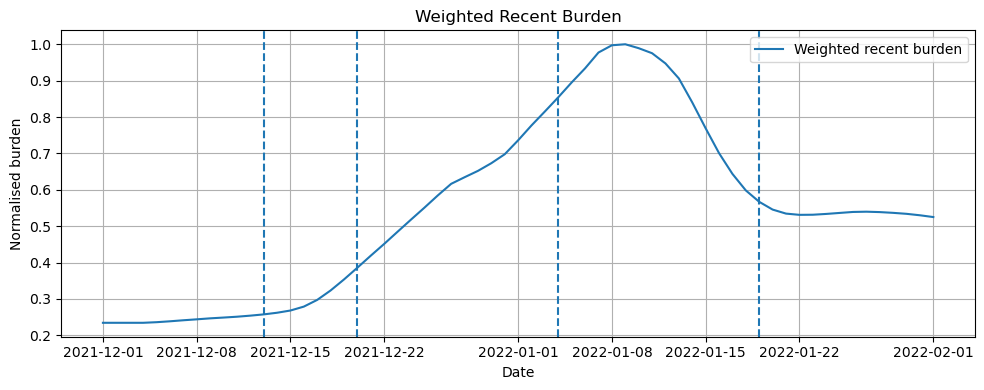


Fitting finished
Success: True
Message: CONVERGENCE: REL_REDUCTION_OF_F_<=_FACTR*EPSMCH
rho: 1.1166541604308733
I0: 197113.57142838163
gamma: 0.14285714285714285
MSE: 82150846.00593731
RMSE: 9063.710388463287
log_MSE: 0.005414038904505236

Estimated segment parameters:
Segment 1: beta0 = 0.223325, k = 0.949454
Segment 2: beta0 = 0.286032, k = 0.961379
Segment 3: beta0 = 0.212638, k = 0.120465
Segment 4: beta0 = 0.158862, k = 0.287477
Segment 5: beta0 = 0.238909, k = 0.995728


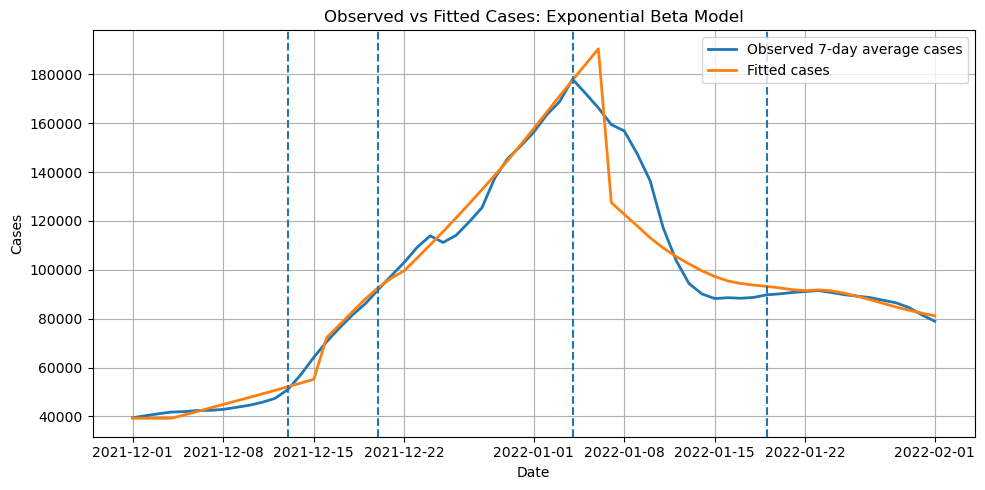

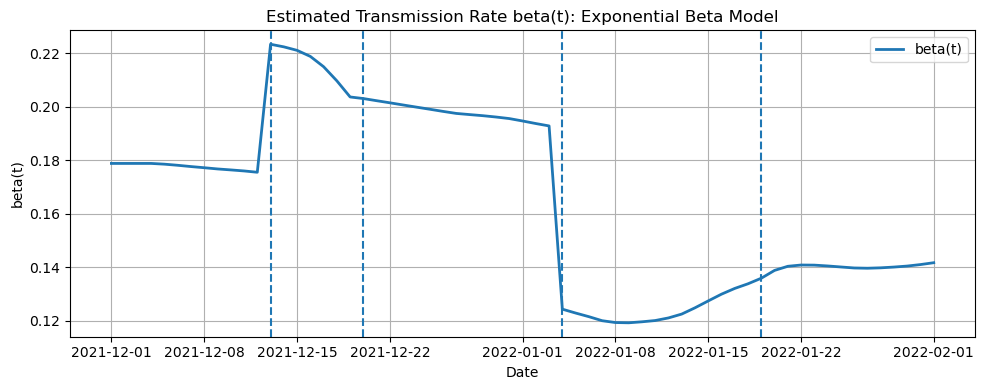


Segment summary:
   segment  start_date    end_date  beta_start  beta_end  beta_mean  \
0        1  2021-12-01  2021-12-12    0.178732  0.175431   0.177536   
1        2  2021-12-13  2021-12-19    0.223267  0.203570   0.216187   
2        3  2021-12-20  2022-01-03    0.202975  0.192744   0.197838   
3        4  2022-01-04  2022-01-18    0.124265  0.133756   0.123845   
4        5  2022-01-19  2022-02-01    0.135836  0.141625   0.139906   

   observed_mean_cases  fitted_mean_cases  model_mean_incidence  
0         42785.380952       43468.849380          42154.251031  
1         69536.081633       68817.158604          78017.695076  
2        127234.695238      128597.334269         130869.399187  
3        125095.752381      122046.403351          92911.880543  
4         87905.071429       88400.071434          76614.460391  


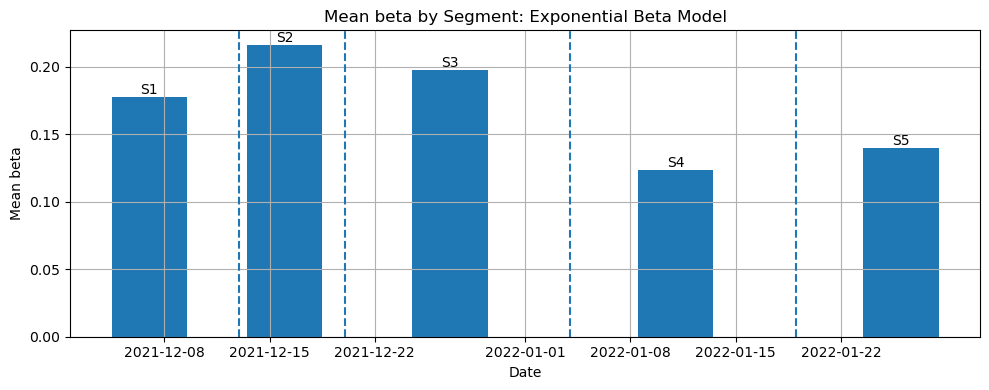


Saved:
../results/exp_beta_fitting_cases.png
../results/exp_beta_fitting_beta.png
../results/exp_beta_segment_summary.csv
../results/exp_beta_fitting_paths.csv


In [3]:
# =========================================================
# Exponential beta fitting only
#
# Purpose:
# Fit the factual behavioural SIR model only.
# No counterfactual experiment is included in this file.
#
# Model:
#   beta_j(t) = beta0_j * exp(-k_j * B(t))
#
# where B(t) is the exponentially weighted recent reported burden.
# =========================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

# =========================================================
# BLOCK 1: data + weighted recent burden
# =========================================================

# load data
df = pd.read_csv("../data/uk_final.csv")
df["date"] = pd.to_datetime(df["date"])

# fitting window
df_fit = df[(df["date"] >= "2021-12-01") & (df["date"] <= "2022-02-01")].copy()
df_fit = df_fit.reset_index(drop=True)

dates = df_fit["date"].reset_index(drop=True)
obs_cases = df_fit["cases_7d"].values.astype(float)
T = len(obs_cases)

# fixed settings
tau = 3
gamma = 1 / 7
N = 67_000_000

# breakpoints
break_dates = ["2021-12-13", "2021-12-20", "2022-01-04", "2022-01-19"]
break_indices = [int(np.where(dates == pd.Timestamp(d))[0][0]) for d in break_dates]


def get_segment_bounds(T, break_indices):
    bounds = [0] + break_indices + [T]
    return [(bounds[i], bounds[i + 1]) for i in range(len(bounds) - 1)]


segment_bounds = get_segment_bounds(T, break_indices)
n_seg = len(segment_bounds)

print("Break dates:", break_dates)
print("Break indices:", break_indices)
print("Segment bounds:", segment_bounds)

# delay function

def apply_delay(x, tau):
    y = np.empty_like(x)
    if tau <= 0:
        return x.copy()
    y[:tau] = x[0]
    y[tau:] = x[:-tau]
    return y


obs_delayed = apply_delay(obs_cases, tau)

# =========================================================
# Weighted recent burden
# =========================================================

L = 7
lam = 0.75

weights = np.array([lam ** ell for ell in range(L)], dtype=float)
weights = weights / weights.sum()

burden = np.zeros(T)

for t in range(T):
    vals = []
    wts = []

    for ell in range(L):
        idx = t - ell
        if idx >= 0:
            vals.append(obs_delayed[idx])
            wts.append(weights[ell])

    vals = np.array(vals, dtype=float)
    wts = np.array(wts, dtype=float)
    wts = wts / wts.sum()

    burden[t] = np.sum(wts * vals)

# normalize burden to [0, 1]
burden = burden / np.max(burden)

# plot burden
plt.figure(figsize=(10, 4))
plt.plot(dates, burden, label="Weighted recent burden")
for d in break_dates:
    plt.axvline(pd.Timestamp(d), linestyle="--")
plt.legend()
plt.title("Weighted Recent Burden")
plt.xlabel("Date")
plt.ylabel("Normalised burden")
plt.grid()
plt.tight_layout()
plt.show()

# =========================================================
# BLOCK 2: exponential beta model
# =========================================================


def get_segment_index(t, segment_bounds):
    for j, (a, b) in enumerate(segment_bounds):
        if a <= t < b:
            return j
    return len(segment_bounds) - 1


# exponential beta formula:
# beta_j(t) = beta0_j * exp(-k_j * B(t))

def beta_t(t, params):
    j = get_segment_index(t, segment_bounds)
    p = params[j]
    B = burden[t]
    beta = p["beta0"] * np.exp(-p["k"] * B)
    return max(1e-8, beta)


# unpack parameters
# theta = [beta0_1, k_1, beta0_2, k_2, ..., beta0_5, k_5, rho, I0]

def unpack(theta):
    params = []
    pos = 0

    for _ in range(n_seg):
        params.append({
            "beta0": theta[pos],
            "k": theta[pos + 1],
        })
        pos += 2

    rho = theta[pos]
    I0 = theta[pos + 1]

    return params, rho, I0


# =========================================================
# BLOCK 3: discrete-time SIR simulation
# =========================================================


def simulate(theta):
    params, rho, I0 = unpack(theta)

    S = np.zeros(T)
    I = np.zeros(T)
    R = np.zeros(T)
    beta_path = np.zeros(T)
    incidence = np.zeros(T)

    S[0] = N - I0
    I[0] = I0
    R[0] = 0.0

    for t in range(T):
        b = beta_t(t, params)
        beta_path[t] = b

        incidence[t] = b * S[t] * I[t] / N

        if t < T - 1:
            new_inf = incidence[t]
            new_rec = gamma * I[t]

            S[t + 1] = max(0.0, S[t] - new_inf)
            I[t + 1] = max(0.0, I[t] + new_inf - new_rec)
            R[t + 1] = max(0.0, R[t] + new_rec)

    fitted_cases = rho * apply_delay(incidence, tau)

    return {
        "S": S,
        "I": I,
        "R": R,
        "beta_path": beta_path,
        "incidence": incidence,
        "fitted_cases": fitted_cases,
        "params": params,
        "rho": rho,
        "I0": I0,
    }


# =========================================================
# BLOCK 4: loss function and optimisation
# =========================================================


def loss(theta):
    try:
        sim = simulate(theta)
        fitted = sim["fitted_cases"]

        if np.any(np.isnan(fitted)) or np.any(np.isinf(fitted)):
            return 1e10
        if np.any(fitted < 0):
            return 1e10

        return np.mean((np.log(fitted + 1) - np.log(obs_cases + 1)) ** 2)

    except Exception:
        return 1e10


# initial values and bounds
x0 = []
bounds = []

for _ in range(n_seg):
    x0 += [0.25, 1.0]             # beta0_j, k_j
    bounds += [(1e-6, 2.0), (0.0, 20.0)]

x0 += [1.0, obs_cases[0] * 5]     # rho, I0
bounds += [(1e-6, 10.0), (1.0, 5_000_000.0)]

x0 = np.array(x0, dtype=float)

res = minimize(
    loss,
    x0,
    bounds=bounds,
    method="L-BFGS-B",
)

theta_hat = res.x
best = simulate(theta_hat)

# diagnostics
mse = np.mean((best["fitted_cases"] - obs_cases) ** 2)
rmse = np.sqrt(mse)
log_mse = np.mean((np.log(best["fitted_cases"] + 1) - np.log(obs_cases + 1)) ** 2)

print("\nFitting finished")
print("Success:", res.success)
print("Message:", res.message)
print("rho:", best["rho"])
print("I0:", best["I0"])
print("gamma:", gamma)
print("MSE:", mse)
print("RMSE:", rmse)
print("log_MSE:", log_mse)

print("\nEstimated segment parameters:")
for j, p in enumerate(best["params"], start=1):
    print(f"Segment {j}: beta0 = {p['beta0']:.6f}, k = {p['k']:.6f}")

# =========================================================
# BLOCK 5: plots
# =========================================================

beta_path = best["beta_path"]
fitted_cases = best["fitted_cases"]
incidence = best["incidence"]

# observed vs fitted cases
plt.figure(figsize=(10, 5))
plt.plot(dates, obs_cases, label="Observed 7-day average cases", linewidth=2)
plt.plot(dates, fitted_cases, label="Fitted cases", linewidth=2)

for d in break_dates:
    plt.axvline(pd.Timestamp(d), linestyle="--")

plt.title("Observed vs Fitted Cases: Exponential Beta Model")
plt.xlabel("Date")
plt.ylabel("Cases")
plt.legend()
plt.grid()
plt.tight_layout()
plt.savefig("../results/exp_beta_fitting_cases.png", dpi=300, bbox_inches="tight")
plt.show()

# beta(t)
plt.figure(figsize=(10, 4))
plt.plot(dates, beta_path, label="beta(t)", linewidth=2)

for d in break_dates:
    plt.axvline(pd.Timestamp(d), linestyle="--")

plt.title("Estimated Transmission Rate beta(t): Exponential Beta Model")
plt.xlabel("Date")
plt.ylabel("beta(t)")
plt.legend()
plt.grid()
plt.tight_layout()
plt.savefig("../results/exp_beta_fitting_beta.png", dpi=300, bbox_inches="tight")
plt.show()

# =========================================================
# BLOCK 6: segment summary
# =========================================================

summary = []

for j, (a, b) in enumerate(segment_bounds):
    seg_beta = beta_path[a:b]
    seg_obs = obs_cases[a:b]
    seg_fit = fitted_cases[a:b]
    seg_inc = incidence[a:b]

    summary.append({
        "segment": j + 1,
        "start_date": dates.iloc[a].strftime("%Y-%m-%d"),
        "end_date": dates.iloc[b - 1].strftime("%Y-%m-%d"),
        "beta_start": float(seg_beta[0]),
        "beta_end": float(seg_beta[-1]),
        "beta_mean": float(np.mean(seg_beta)),
        "observed_mean_cases": float(np.mean(seg_obs)),
        "fitted_mean_cases": float(np.mean(seg_fit)),
        "model_mean_incidence": float(np.mean(seg_inc)),
    })

seg_df = pd.DataFrame(summary)
print("\nSegment summary:")
print(seg_df)

seg_df.to_csv("../results/exp_beta_segment_summary.csv", index=False)

# mean beta by segment
mid_dates = [dates.iloc[(a + b) // 2] for (a, b) in segment_bounds]

plt.figure(figsize=(10, 4))
plt.bar(mid_dates, seg_df["beta_mean"], width=5)

for d in break_dates:
    plt.axvline(pd.Timestamp(d), linestyle="--")

for i, row in seg_df.iterrows():
    plt.text(
        mid_dates[i],
        row["beta_mean"],
        f"S{int(row['segment'])}",
        ha="center",
        va="bottom",
        fontsize=10,
    )

plt.title("Mean beta by Segment: Exponential Beta Model")
plt.xlabel("Date")
plt.ylabel("Mean beta")
plt.grid()
plt.tight_layout()
plt.savefig("../results/exp_beta_segment_mean.png", dpi=300, bbox_inches="tight")
plt.show()

# save full paths
paths_df = pd.DataFrame({
    "date": dates,
    "observed_cases": obs_cases,
    "burden": burden,
    "fitted_cases": fitted_cases,
    "beta_path": beta_path,
    "incidence": incidence,
})

paths_df.to_csv("../results/exp_beta_fitting_paths.csv", index=False)

print("\nSaved:")
print("../results/exp_beta_fitting_cases.png")
print("../results/exp_beta_fitting_beta.png")
print("../results/exp_beta_segment_summary.csv")
print("../results/exp_beta_fitting_paths.csv")
